# 🔹 Paso 1: Cargar y validar la calidad de los datos

---

# 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarnos con la estructura de los datasets del negocio antes de analizarlos.

**Instrucciones:**

- Se importan las librerias necesarias.
- Se cargan los archivos:
  - `rappiplus_orders_raw.csv`
  - `rappiplus_catalog.csv`
  - `rappiplus_marketing_spend.csv`
- Se almacenan los datasets en las variables:
  - `orders`, `catalog`, `marketing`
- Se exploran cada uno de los datasets.

In [111]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
import matplotlib.ticker as ticker
from statsmodels.stats.proportion import proportions_ztest
import plotly.express as px

In [112]:
# cargar archivos
orders = pd.read_csv("rappiplus_orders_raw.csv")
catalog = pd.read_csv("rappiplus_catalog.csv")
marketing = pd.read_csv("rappiplus_marketing_spend.csv")

In [113]:
# explorar datasets
orders.head()

,id_pedido,id_usuario,fecha_hora_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento,monto_total
0,order_0,user_6993,2025-05-22,Argentina,desktop,organic,Jacket-Winter-M,Moda,2.0,332.69,0.0,665.37
1,order_1,user_1329,2025-06-15,Mexico,desktop,paid_search,Tablet-Standard-64GB,Electronica,1.0,176.86,5.0,171.86
2,order_2,user_3194,2025-05-02,Argentina,desktop,social,Blender-XL-Red,Hogar,2.0,102.99,10.0,195.99
3,order_3,user_4510,2025-06-09,Colombia,mobile,social,Tablet-Standard-64GB,Electronica,1.0,257.87,15.0,242.87
4,order_4,user_5044,2025-03-30,Argentina,desktop,paid_search,Blender-XL-Red,Hogar,1.0,336.28,0.0,336.28


In [114]:
catalog.head()

,nombre_producto,categoria_producto,costo_unitario,proveedor
0,Laptop-Gaming-16GB,Electrónica,280.68,"Fuller, Pena and Myers"
1,Phone-Pro-128GB,Electrónica,10.12,King Ltd
2,Tablet-Standard-64GB,Electrónica,25.21,Bowers LLC
3,Blender-XL-Red,Hogar,176.64,Long-Reid
4,Vacuum-Pro-Black,Hogar,16.60,"Rivera, Carr and Finley"


In [115]:
marketing.head()

,fecha,pais,id_campaña,canal,gasto
0,2025-01-01,Mexico,organic_Mexico,organic,2446.25
1,2025-01-01,Mexico,paid_search_Mexico,paid_search,2704.34
2,2025-01-01,Mexico,social_Mexico,social,2045.01
3,2025-01-01,Colombia,organic_Colombia,organic,2597.21
4,2025-01-01,Colombia,paid_search_Colombia,paid_search,1771.40


---

# 1.2 Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Se valida y convierten fechas al formato correcto  
- Se normalizan las variables numéricas   
- Se verifica la consistencia de montos  
- Se eliminan duplicados  
- Se revisan variables categóricas 

In [116]:
#Correción de formato en columnas tipo 'fecha'

##Dataset orders
orders["fecha_hora_pedido"] = pd.to_datetime(orders["fecha_hora_pedido"])
orders.rename(columns={"fecha_hora_pedido":"fecha_pedido"}, inplace = True)

##Dataset marketing
marketing["fecha"] = pd.to_datetime(marketing["fecha"])

In [117]:
##Dataset orders

"""Columna 'Pais' - Se corrigen valores. Adicionalmente, se reemplazan 300 valores, inicialmente 
categorizados como 'Indeterminados', por la moda de la columna"""

orders["pais"] = np.where(
    orders["pais"] == "argentina", "Argentina", orders["pais"],)

orders["pais"].fillna("Indeterminado", inplace = True)
orders["pais"] = orders["pais"].replace("Indeterminado", orders["pais"].mode()[0])

"""Columna 'Dispositivo' - Se imputan los valores faltantes de esta columna con la moda."""

orders["dispositivo"] = orders["dispositivo"].fillna("desktop")

"""Columna 'Fuente de referencia' - Se imputan los valores faltantes de esta columna con la moda."""

orders["fuente_referencia"] = orders["fuente_referencia"].fillna(orders["fuente_referencia"].mode()[0])

"""Columna 'Categoria de producto' - Se obtienen los valores faltantes de esta columna a partir del "nombre_producto" """

mapa_categorias = {
    # Moda
    'sneakers': 'Moda',
    'shoes': 'Moda',
    'shirt': 'Moda',
    'jacket': 'Moda',
    
    # Hogar
    'vacuum': 'Hogar',
    'blender': 'Hogar',
    'chair': 'Hogar',
    
    # Tecnología
    'laptop': 'Electronica',
    'phone': 'Electronica',
    'tablet': 'Electronica'
}

primera_palabra = orders['nombre_producto'].str.split('-').str[0].str.lower()

orders['categoria_producto'] = orders['categoria_producto'].fillna(
    primera_palabra.map(mapa_categorias)
)

"""Eliminación de duplicados - Se eliminan 100 registros dupicados"""
orders.drop_duplicates(inplace=True)

"""Cálculo de valores absolutos - Se corrigen los valores negativos (<0) a través de la función '.abs'""" 
orders["cantidad"] = orders["cantidad"].abs()
orders["monto_total"] = orders["monto_total"].abs()

"""Eliminación de valores faltantes - Se evidencian algunas filas con valores faltantes en las columnas
'nombre_producto', 'categoria_producto' y 'precio_unitario', 'monto_descuento', 'cantidad'; tras determinar
que unicamente representan ≈0.1% del dataset 'Orders', se eliminan"""

orders= orders.dropna(subset=["precio_unitario"])
orders= orders.dropna(subset=["nombre_producto"])

orders["cantidad"] = np.where(
    orders["cantidad"] == 10000, 1, orders["cantidad"],
)

orders["cantidad"] = np.where(
    orders["cantidad"] == 20000, 2, orders["cantidad"],
)

orders["monto_total"] = (orders["precio_unitario"] * orders["cantidad"])-orders["monto_descuento"]

##Dataset Marketing 

"""Canal - Se corrigen valores nulos de esta columna a partir de "id_campaña", separando el canal del país."""

marketing["canal"] = marketing["canal"].fillna(
    marketing["id_campaña"].str.rsplit("_",n=1).str[0])

---
**📦 Exportación**: Tras finalizar la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [118]:
# exportar datasets

orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

---

# 🔹 Paso 2: Analizar si el negocio es rentable

# 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)? 
- ¿Cuál es el costo total? 
- ¿Cuánto se ha invertido en marketing? 
- ¿El negocio es rentable? (calcular profit)  
---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden? 
- ¿Cuál es la cantidad promedio de productos por orden? 
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal? 

In [119]:
#Uniones
rent_orders = pd.merge(
    orders,
    catalog,
    on="nombre_producto",
    how="left"
)

rent_orders.drop(columns=["categoria_producto_y", "proveedor"], inplace=True)
rent_orders.rename(columns={"categoria_producto_x":"categoria_producto" , "costo_unitario":"costo_total"}, inplace=True)

rent_orders["costo_total"] = rent_orders["costo_total"] * rent_orders["cantidad"] 

In [120]:
#Calculo de Rentabilidad

#Ingreso total (revenue)
ingreso_total = orders["monto_total"].sum()
print(f"El ingreso total es ${ingreso_total:,.0f}\n")

#Cuál es el costo total? 
costo_total = rent_orders["costo_total"].sum()
print(f"El costo total es: ${costo_total:,.0f}\n")

#Cuánto se ha invertido en marketing
marketing_inv = marketing["gasto"].sum()
print(f"El total de inversión en marketing es: ${marketing_inv:,.2f}\n")

#Profit
profit = ingreso_total - costo_total
print(f"El profit es: ${profit:,.0f}\n")

El ingreso total es $9,615,402

El costo total es: $3,832,849

El total de inversión en marketing es: $2,871,843.53

El profit es: $5,782,552



In [142]:
#Creación de df - Rentabilidad

df_rentabilidad = rent_orders.groupby("nombre_producto")["monto_total","costo_total"].sum().reset_index()

df_rentabilidad.rename(columns={"monto_total":"Ingresos Totales", "costo_total":"Costos Totales"}, inplace=True)

df_rentabilidad["Ingresos Totales"] = df_rentabilidad["Ingresos Totales"].astype(float)  
df_rentabilidad["Costos Totales"] = df_rentabilidad["Costos Totales"].astype(float) 

df_rentabilidad["Profit"] = df_rentabilidad["Ingresos Totales"] - df_rentabilidad["Costos Totales"] 

In [143]:
df_rentabilidad["Ingresos Totales"] = df_rentabilidad["Ingresos Totales"].astype(int)
df_rentabilidad["Costos Totales"] = df_rentabilidad["Costos Totales"].astype(int)
df_rentabilidad["Profit"] = df_rentabilidad["Profit"].astype(int)

In [144]:
df_rentabilidad

,nombre_producto,Ingresos Totales,Costos Totales,Profit
0,Blender-XL-Red,1611574,1109122,502451
1,Jacket-Winter-M,1606586,1184323,422263
2,Laptop-Gaming-16GB,1088907,1182224,-93316
3,Phone-Pro-128GB,1058281,41947,1016334
4,Sneakers-Urban-42,1566076,106220,1459856
5,Tablet-Standard-64GB,1062922,104697,958225
6,Vacuum-Pro-Black,1621052,104314,1516737


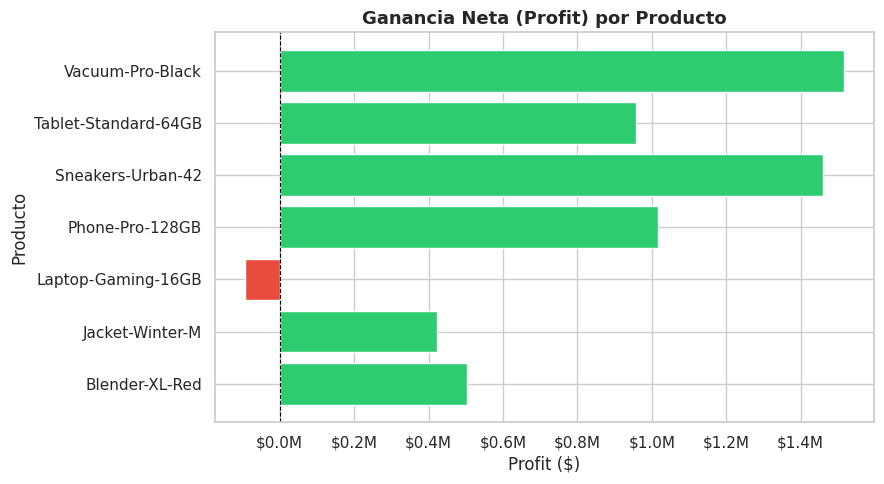

In [124]:
# Definir colores según si el Profit es positivo o negativo
colores = ["#2ecc71" if x > 0 else "#e74c3c" for x in df_rentabilidad["Profit"]]

plt.figure(figsize=(9, 5))
bars = plt.barh(df_rentabilidad["nombre_producto"], df_rentabilidad["Profit"], color=colores)

plt.axvline(0, color="black", linewidth=0.8, linestyle="--")
plt.title("Ganancia Neta (Profit) por Producto", fontsize=13, fontweight="bold")
plt.xlabel("Profit ($)")
plt.ylabel("Producto")

# Formato en el eje X
formatter = ticker.FuncFormatter(lambda x, pos: f"${x*1e-6:.1f}M")
plt.gca().xaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()


### Análisis de Ganancia por Producto
Tras visualizar el profit del semestre asociado a cada producto, evidenciamos que el producto 'Laptop-Gaming-16GB' cuenta con un valor negativo.
Esta desviación representa un impacto directo sobre el margen global de la categoría
Por otro lado, el producto 'Vacuum-Pro-Black' destaca como el producto que más ganancia representa


In [125]:
#Comportamiento de ventas

#Ticket promedio  
ticket_promedio = orders["monto_total"].mean()
print(f"El valor del ticket promedio es: ${ticket_promedio:.2f}\n")

#Cuál es la cantidad promedio de productos por orden

promedio_orden = orders["cantidad"].mean()
print(f"Cantidad promedio de productos por orden:{promedio_orden:.1f} \n")

#Cuál es el producto más vendido?
best_seller = orders["nombre_producto"].value_counts().index[0]
best_seller1 = orders["nombre_producto"].value_counts().iloc[0]
print(f"El producto más vendido fue '{best_seller}', con un total de {best_seller1:,.2f} ventas\n")

#Cuánto se ha gastado en marketing por canal? 
costo_marketing = marketing.groupby("canal")["gasto"].sum().reset_index()
costo_marketing["gasto"] = costo_marketing["gasto"].map("{:,.2f}".format)

print("Gastos por canal\n")
costo_marketing

El valor del ticket promedio es: $385.85

Cantidad promedio de productos por orden:1.5 

El producto más vendido fue 'Blender-XL-Red', con un total de 4,176.00 ventas

Gastos por canal



,canal,gasto
0,organic,"972,650.96"
1,paid_search,"922,374.20"
2,social,"976,818.37"


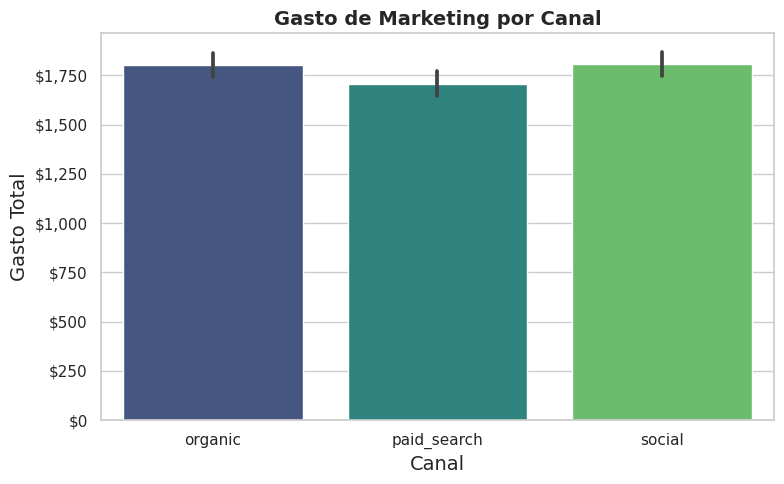

In [126]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=marketing, x="canal", y="gasto", palette="viridis"
)

plt.title("Gasto de Marketing por Canal", fontsize=14, fontweight="bold")
plt.xlabel("Canal", fontsize=14)
plt.ylabel("Gasto Total", fontsize=14)

ax.yaxis.set_major_formatter("${x:,.0f}")

plt.tight_layout()
plt.show()

### Análisis de Gastos en Marketing 
Al visualizar los gastos de marketing segmentados por canal, evidenciamos que a pesar de contar con cifras homogeneas, el canal 'Social' representa un gasto ligeramente mayor

# 🔹Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [127]:
import pandas as pd
from sqlalchemy import create_engine

# ======================
# Conexión
# ======================
db_config = {
    'user': 'practicum_student',
    'pwd': 'QnmDH8Sc2TQLvy2G3Vvh7',
    'host': 'yp-trainers-practicum.cluster-czs0gxyx2d8w.us-east-1.rds.amazonaws.com',
    'port': 5432,
    'db': 'data-analyst-production-db-en'
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [128]:
# Construcción del funnel global
# =========================
funnel_global= """
--Creación de funnel

WITH first_visits AS (
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'first_visit'
),
adds_to_cart AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'add_to_cart'
),
select_items AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'select_item'
),
begins_checkout AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'begin_checkout'
),
adds_payment_info AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'add_payment_info'
),
purchases AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'purchase'
),
funnel_count AS(
SELECT fv.nombre_evento,
    COUNT(fv.id_usuario) AS usuarios_first_visit,
    COUNT(si.id_usuario) AS usuarios_select_item,
    COUNT(ac.id_usuario) AS usuarios_add_to_cart,
    COUNT(bc.id_usuario) AS usuarios_begin_checkout,
    COUNT(ap.id_usuario) AS usuarios_add_payment_info,
    COUNT(pc.id_usuario) AS usuarios_purchase
FROM first_visits AS fv
LEFT JOIN select_items AS si
    ON fv.id_usuario = si.id_usuario AND fv.pais = si.pais
LEFT JOIN adds_to_cart AS ac
    ON fv.id_usuario = ac.id_usuario AND fv.pais = ac.pais
LEFT JOIN begins_checkout AS bc
    ON fv.id_usuario = bc.id_usuario AND fv.pais = bc.pais
LEFT JOIN adds_payment_info AS ap
    ON fv.id_usuario = ap.id_usuario AND fv.pais = ap.pais
LEFT JOIN purchases AS pc
    ON fv.id_usuario = pc.id_usuario AND fv.pais = pc.pais
GROUP BY fv.nombre_evento
)




SELECT usuarios_first_visit, usuarios_select_item, usuarios_add_to_cart, usuarios_begin_checkout,
    usuarios_add_payment_info, usuarios_purchase
FROM funnel_count;
"""

funnel_general = pd.read_sql(funnel_global, con=engine)
funnel_general.head()

,usuarios_first_visit,usuarios_select_item,usuarios_add_to_cart,usuarios_begin_checkout,usuarios_add_payment_info,usuarios_purchase
0,7796,7393,7439,7031,6088,6068


In [129]:
# Construcción del funnel segmentado por país
# =========================

funnel_segmentado= """
--Creación de funnel

WITH first_visits AS (
SELECT DISTINCT id_usuario, pais
FROM events
WHERE nombre_evento = 'first_visit'
),
adds_to_cart AS(
SELECT DISTINCT id_usuario, pais
FROM events
WHERE nombre_evento = 'add_to_cart'
),
select_items AS(
SELECT DISTINCT id_usuario, pais
FROM events
WHERE nombre_evento = 'select_item'
),
begins_checkout AS(
SELECT DISTINCT id_usuario, pais
FROM events
WHERE nombre_evento = 'begin_checkout'
),
adds_payment_info AS(
SELECT DISTINCT id_usuario, pais
FROM events
WHERE nombre_evento = 'add_payment_info'
),
purchases AS(
SELECT DISTINCT id_usuario, pais
FROM events
WHERE nombre_evento = 'purchase'
),
funnel_count AS(
SELECT fv.pais,
    COUNT(fv.id_usuario) AS usuarios_first_visit,
    COUNT(si.id_usuario) AS usuarios_select_item,
    COUNT(ac.id_usuario) AS usuarios_add_to_cart,
    COUNT(bc.id_usuario) AS usuarios_begin_checkout,
    COUNT(ap.id_usuario) AS usuarios_add_payment_info,
    COUNT(pc.id_usuario) AS usuarios_purchase
FROM first_visits AS fv
LEFT JOIN select_items AS si
    ON fv.id_usuario = si.id_usuario AND fv.pais = si.pais
LEFT JOIN adds_to_cart AS ac
    ON fv.id_usuario = ac.id_usuario AND fv.pais = ac.pais
LEFT JOIN begins_checkout AS bc
    ON fv.id_usuario = bc.id_usuario AND fv.pais = bc.pais
LEFT JOIN adds_payment_info AS ap
    ON fv.id_usuario = ap.id_usuario AND fv.pais = ap.pais
LEFT JOIN purchases AS pc
    ON fv.id_usuario = pc.id_usuario AND fv.pais = pc.pais
GROUP BY fv.pais
)





SELECT pais,usuarios_first_visit, usuarios_select_item, usuarios_add_to_cart, usuarios_begin_checkout,
    usuarios_add_payment_info, usuarios_purchase
FROM funnel_count;
"""




funnel_pais = pd.read_sql(funnel_segmentado, con=engine)
funnel_pais.head()

,pais,usuarios_first_visit,usuarios_select_item,usuarios_add_to_cart,usuarios_begin_checkout,usuarios_add_payment_info,usuarios_purchase
0,Colombia,2635,2489,2510,2391,2064,2052
1,Argentina,2543,2418,2436,2290,1971,2012
2,Mexico,2618,2486,2493,2350,2053,2004


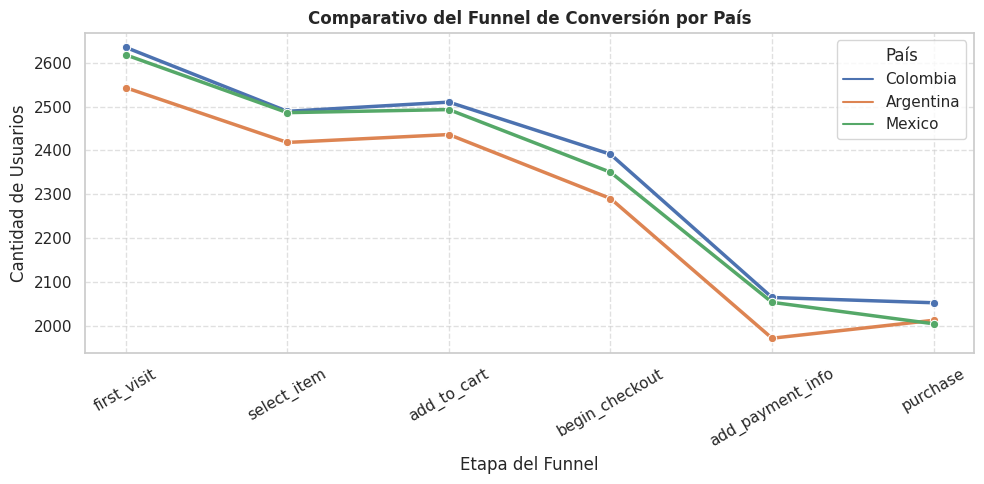

In [130]:
df_long = funnel_pais.melt(id_vars="pais", var_name="etapa", value_name="usuarios")
df_long["etapa"] = df_long["etapa"].str.replace("usuarios_", "")

# 2. Crear el gráfico de líneas
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=df_long, x="etapa", y="usuarios", hue="pais", marker="o", linewidth=2.5
)

plt.title("Comparativo del Funnel de Conversión por País", fontweight="bold")
plt.xlabel("Etapa del Funnel")
plt.ylabel("Cantidad de Usuarios")
plt.xticks(rotation=30)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(title="País")

plt.tight_layout()
plt.show()

### Comparación del Funnel por País
Este gráfico nos permite visualizar a detalle la trayectoria del proceso de conversión en cada país. Asimismo, confirmamos que el paso de mayor fricción se es añadir la información de pago.

In [131]:
# PARTE 1: Totales del funnel
# ======================

query_totals = """
WITH first_visits AS (
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'first_visit'
),
adds_to_cart AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'add_to_cart'
),
select_items AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'select_item'
),
begins_checkout AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'begin_checkout'
),
adds_payment_info AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'add_payment_info'
),
purchases AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'purchase'
),
funnel_count AS(
SELECT fv.nombre_evento,
    COUNT(fv.id_usuario) AS usuarios_first_visit,
    COUNT(si.id_usuario) AS usuarios_select_item,
    COUNT(ac.id_usuario) AS usuarios_add_to_cart,
    COUNT(bc.id_usuario) AS usuarios_begin_checkout,
    COUNT(ap.id_usuario) AS usuarios_add_payment_info,
    COUNT(pc.id_usuario) AS usuarios_purchase
FROM first_visits AS fv
LEFT JOIN select_items AS si
    ON fv.id_usuario = si.id_usuario AND fv.pais = si.pais
LEFT JOIN adds_to_cart AS ac
    ON fv.id_usuario = ac.id_usuario AND fv.pais = ac.pais
LEFT JOIN begins_checkout AS bc
    ON fv.id_usuario = bc.id_usuario AND fv.pais = bc.pais
LEFT JOIN adds_payment_info AS ap
    ON fv.id_usuario = ap.id_usuario AND fv.pais = ap.pais
LEFT JOIN purchases AS pc
    ON fv.id_usuario = pc.id_usuario AND fv.pais = pc.pais
GROUP BY fv.nombre_evento
)

SELECT usuarios_first_visit, usuarios_select_item, usuarios_add_to_cart, usuarios_begin_checkout,
    usuarios_add_payment_info, usuarios_purchase
FROM funnel_count;
"""

totals = pd.read_sql(query_totals, con=engine)
totals

,usuarios_first_visit,usuarios_select_item,usuarios_add_to_cart,usuarios_begin_checkout,usuarios_add_payment_info,usuarios_purchase
0,7796,7393,7439,7031,6088,6068


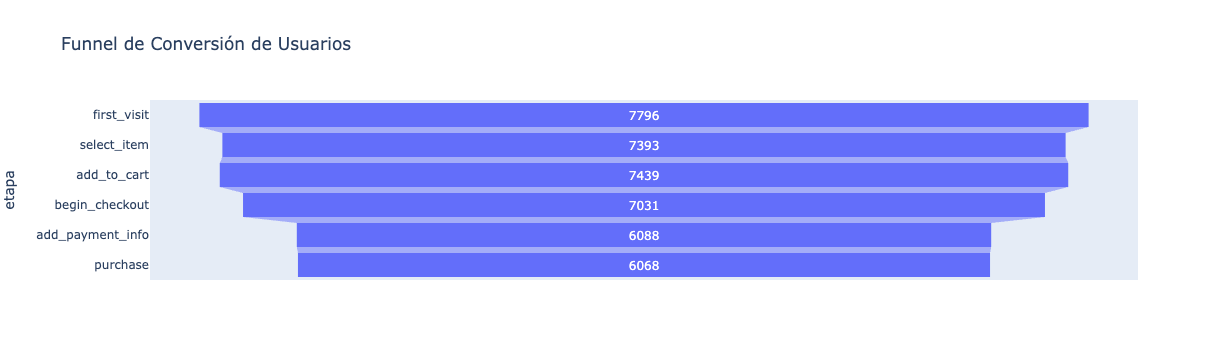

In [132]:
# 1. Transformar la tabla de formato ancho a largo
df_funnel = totals.melt(var_name="etapa", value_name="usuarios")

# Opcional: limpiar los nombres de las etapas quitando el prefijo "usuarios_"
df_funnel["etapa"] = df_funnel["etapa"].str.replace("usuarios_", "")

# 2. Crear el gráfico de embudo
fig = px.funnel(
    df_funnel,
    x="usuarios",
    y="etapa",
    title="Funnel de Conversión de Usuarios",
)

fig.show()

### Funnel de Conversión
A través de este funnel evidenciamos un cuello de botella entre los pasos 'Begin checkout' y 'add payment info'

In [133]:
# PARTE 2: Conversiones
# ======================

query_conversion = """
WITH first_visits AS (
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'first_visit'
),
adds_to_cart AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'add_to_cart'
),
select_items AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'select_item'
),
begins_checkout AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'begin_checkout'
),
adds_payment_info AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'add_payment_info'
),
purchases AS(
SELECT DISTINCT id_usuario, pais, nombre_evento
FROM events
WHERE nombre_evento = 'purchase'
),
funnel_count AS(
SELECT fv.nombre_evento,
    COUNT(fv.id_usuario) AS usuarios_first_visit,
    COUNT(si.id_usuario) AS usuarios_select_item,
    COUNT(ac.id_usuario) AS usuarios_add_to_cart,
    COUNT(bc.id_usuario) AS usuarios_begin_checkout,
    COUNT(ap.id_usuario) AS usuarios_add_payment_info,
    COUNT(pc.id_usuario) AS usuarios_purchase
FROM first_visits AS fv
LEFT JOIN select_items AS si
    ON fv.id_usuario = si.id_usuario AND fv.pais = si.pais
LEFT JOIN adds_to_cart AS ac
    ON fv.id_usuario = ac.id_usuario AND fv.pais = ac.pais
LEFT JOIN begins_checkout AS bc
    ON fv.id_usuario = bc.id_usuario AND fv.pais = bc.pais
LEFT JOIN adds_payment_info AS ap
    ON fv.id_usuario = ap.id_usuario AND fv.pais = ap.pais
LEFT JOIN purchases AS pc
    ON fv.id_usuario = pc.id_usuario AND fv.pais = pc.pais
GROUP BY fv.nombre_evento
)

SELECT ROUND(100.0 * usuarios_first_visit / usuarios_first_visit,2) AS pct_usuarios_first_visit,
       ROUND(100.0 * usuarios_select_item / usuarios_first_visit,2) AS pct_usuarios_usuarios_select_item,
       ROUND(100.0 * usuarios_add_to_cart / usuarios_first_visit,2) AS pct_usuarios_usuarios_add_to_cart,
       ROUND(100.0 * usuarios_begin_checkout / usuarios_first_visit,2) AS pct_usuarios_usuarios_begin_checkout,
       ROUND(100.0 * usuarios_add_payment_info / usuarios_first_visit,2) AS pct_usuarios_usuarios_add_payment_info,
       ROUND(100.0 * usuarios_purchase / usuarios_first_visit,2) AS pct_usuarios_usuarios_purchase
FROM funnel_count;
"""

conversion = pd.read_sql(query_conversion, con=engine)
conversion

,pct_usuarios_first_visit,pct_usuarios_usuarios_select_item,pct_usuarios_usuarios_add_to_cart,pct_usuarios_usuarios_begin_checkout,pct_usuarios_usuarios_add_payment_info,pct_usuarios_usuarios_purchase
0,100.0,94.83,95.42,90.19,78.09,77.83


---

# 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users` 
- `user_activity` 

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [134]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head()

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free
3,user_3,2025-03-04,Mexico,desktop,free
4,user_4,2025-02-27,Argentina,desktop,free


In [135]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT *
FROM user_activity
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head()

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1
3,user_0,2025-02-26,28,0
4,user_1,2025-01-14,7,0


In [136]:
# Retención por cohortes
# ======================

query_cohort_retention_final = '''
WITH conjunto AS(
SELECT
    u.*, 
    ua.fecha_actividad, 
    ua.dias_despues_registro, 
    ua.activo
FROM users u
LEFT JOIN user_activity ua 
    ON u.id_usuario = ua.id_usuario
),
baseline AS(SELECT 
    país,
    COUNT(DISTINCT id_usuario) AS usuarios_base,
    COUNT(DISTINCT CASE WHEN dias_despues_registro >= 7 THEN id_usuario END) AS cohorte_D7,
    COUNT(DISTINCT CASE WHEN dias_despues_registro >= 14 THEN id_usuario END) AS cohorte_D14,
    COUNT(DISTINCT CASE WHEN dias_despues_registro >= 21 THEN id_usuario END) AS cohorte_D21,
    COUNT(DISTINCT CASE WHEN dias_despues_registro >= 28 THEN id_usuario END) AS cohorte_D28
FROM conjunto
WHERE activo = 1
GROUP BY país
ORDER BY país),
retencion_pct AS(SELECT 
    país,
    ROUND(cohorte_D7*100.0/NULLIF(usuarios_base,0),1) AS cohorte_D7_pct,
    ROUND(cohorte_D14*100.0/NULLIF(usuarios_base,0),1) AS cohorte_D14_pct,
    ROUND(cohorte_D21*100.0/NULLIF(usuarios_base,0),1) AS cohorte_D21_pct,
    ROUND(cohorte_D28*100.0/NULLIF(usuarios_base,0),1) AS cohorte_D28_pct
FROM baseline)

SELECT *
FROM retencion_pct
'''

# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final.head(5)

,país,cohorte_d7_pct,cohorte_d14_pct,cohorte_d21_pct,cohorte_d28_pct
0,Argentina,100.0,91.8,74.6,46.3
1,Colombia,100.0,90.8,74.6,46.7
2,Mexico,100.0,90.9,74.1,48.2


In [137]:
cohorte_final.style.background_gradient(
    cmap="RdYlGn",  # Red-Yellow-Green (Semaforización)
    subset=[
        "cohorte_d7_pct",
        "cohorte_d14_pct",
        "cohorte_d21_pct",
        "cohorte_d28_pct",
    ],  # Columnas numéricas
    vmin=0,
    vmax=100,  # Escala de 0% a 100%
).format(
    "{:.1f}%",
    subset=[
        "cohorte_d7_pct",
        "cohorte_d14_pct",
        "cohorte_d21_pct",
        "cohorte_d28_pct",
    ],
)

,país,cohorte_d7_pct,cohorte_d14_pct,cohorte_d21_pct,cohorte_d28_pct
0,Argentina,100.0%,91.8%,74.6%,46.3%
1,Colombia,100.0%,90.8%,74.6%,46.7%
2,Mexico,100.0%,90.9%,74.1%,48.2%


---

# 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado** 
4. **Interpretar el resultado**  

---
Hipótesis estadística
   - **H₀ (Hipótesis nula):** No existe una diferencia estadisticamente significativa entre la tasa de conversión del grupo de tratamiento y el grupo de control. 
   - **H₁ (Hipótesis alternativa):** Existe una diferencia estadisiticamente significativa entre la tasa de conversión del grupo de tratamiento y el grupo de control, la cual nos permite determinar  la prueba efectuada en uno de los grupos conlleva a un mayor índice de compra. 
   
**Test estadístico:** Z Test  
**Nivel de significancia alpha:** 0.05

In [138]:
# tu código aquí
df_test = pd.read_csv("experiment_checkout_ui.csv")
df_test["timestamp"] = pd.to_datetime(df_test["timestamp"], format="%Y-%m-%d")

z_table = pd.crosstab(df_test["convirtio"], df_test["variante"])

In [139]:
conversion = df_test.groupby("variante")["convirtio"].sum()
totales = df_test.groupby("variante")["convirtio"].count()

In [140]:
exitos = [conversion["control"], conversion["tratamiento"]]
observaciones = [totales["control"], totales["tratamiento"]]

z_stat, p_value = proportions_ztest(exitos, observaciones)
print(f"Estadístico z:{z_stat:.2f}")
print(f"Valor p: {p_value:.2f}")

alpha = 0.05

def z_test_check(pvalue):
    if pvalue < alpha:
        print("Rechazamos la hipótesis nula: hay evidencia de una diferencia.")
    else:
        print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.")

z_test_check(p_value)
exitos, observaciones

Estadístico z:-0.81
Valor p: 0.42
No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.


([779, 820], [4965, 5035])

In [141]:
tasa_control = exitos[0] / observaciones[0]
tasa_tratamiento = exitos[1] / observaciones[1]

print(f"Tasa de conversión del grupo de control: {tasa_control:.2%}")
print(f"Tasa de conversión del grupo de tratamiento: {tasa_tratamiento:.2%}")

Tasa de conversión del grupo de control: 15.69%
Tasa de conversión del grupo de tratamiento: 16.29%


# 🔹 INSIGHTS 
## Situación (S) 
Durante el semestre evaluado, el negocio generó un ingreso total de 9,615,402 USD, alcanzando una ganancia neta (profit) consolidada de 5,782,552 USD. La rentabilidad general del portafolio se mantiene sólida, liderada por productos estrella como 'Vacuum-Pro-Black' (con más de 1.5M en ganancia), 'Sneakers-Urban-42' y 'Phone-Pro-128GB'. Asimismo, la inversión en marketing (2,871,843.53 USD) se encuentra distribuida equitativamente entre los tres canales principales (organic, paid search y social, rondando los ~920K - 976K cada uno).   

## Complicación (C) 
A pesar del rendimiento global positivo, identificamos que'Laptop-Gaming-16GB' es el único producto del portafolio que registra un profit negativo, generando una desviación directa que impacta el margen global de la categoría. Adicionalmente. en el análisis se observa una caída drástica en el volumen de usuarios entre las etapas begin_checkout y add_payment_info, representando el mayor cuello de botella en la conversión.

## Pregunta (Q)
¿Cómo podemos optimizar la estructura de costos y la estrategia de conversión para eliminar la pérdida del producto Laptop-Gaming-16GB y mitigar la fricción en la etapa de pago sin comprometer el alcance comercial?

## Respuesta (A)
Se recomiendan tres líneas de acción prioritarias para el próximo trimestre: 

### Auditoría de Costos y Precios para 'Laptop-Gaming-16GB'
Revisar la estructura de costo de ventas y gastos de adquisición de este producto para recalibrar su precio de venta o reducir promociones hasta devolverlo a un margen positivo.

### Optimización de UX/UI en la Pasarela de Pago
Investigar posibles fallas técnicas o falta de métodos de pago locales en la transición de begin_checkout a add_payment_info para reducir el abandono masivo de usuarios.   

### Reasignación de Pauta Publicitaria: Ajustar la inversión en paid search y social enfocando las campañas en los productos con mayor margen operativo (Vacuum-Pro-Black y Sneakers-Urban-42).

---

# 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión. 

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`


# 📎 Enlace del Dashboard

In [71]:
https://drive.google.com/drive/folders/1Nz4Fr9mTipi5EwPe7F3b3pCqDQa9kQdG?usp=drive_link

SyntaxError: invalid syntax (713071587.py, line 1)